In [5]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    accuracy_score
)

cancer = load_breast_cancer(as_frame=True)

X = cancer.data
y = cancer.target

print("Dataset shape:", X.shape)
print("Target distribution:")
print(y.value_counts())

print("\nClass mapping:")
for label, name in enumerate(cancer.target_names):
    print(label, "=", name)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.33,
    random_state=42,
    stratify=y
)

Dataset shape: (569, 30)
Target distribution:
target
1    357
0    212
Name: count, dtype: int64

Class mapping:
0 = malignant
1 = benign


In [6]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression())
])

params = {
    "model__C": [0.01, 0.1, 1, 5, 10],
    "model__max_iter": [1000, 2000]
}

search = GridSearchCV(
    pipeline,
    param_grid=params,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best CV macro F1:", search.best_score_)

Best parameters: {'model__C': 0.1, 'model__max_iter': 1000}
Best CV macro F1: 0.9743770631884768


Test accuracy: 0.9840425531914894
Test macro F1: 0.9828795191694746

Classification Report:
              precision    recall  f1-score   support

   malignant       0.99      0.97      0.98        70
      benign       0.98      0.99      0.99       118

    accuracy                           0.98       188
   macro avg       0.98      0.98      0.98       188
weighted avg       0.98      0.98      0.98       188



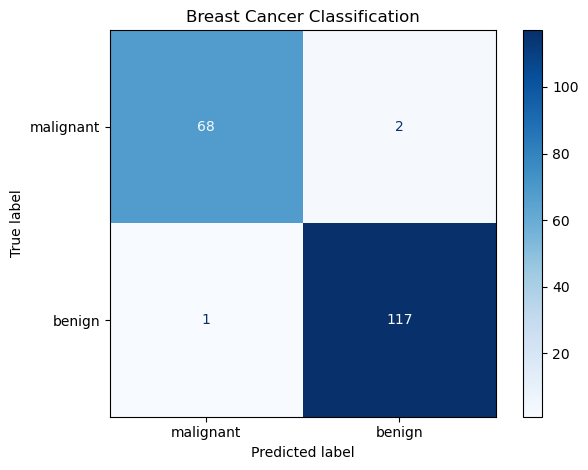

In [7]:
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Test macro F1:", f1_score(y_test, y_pred, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=cancer.target_names
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=cancer.target_names,
    cmap="Blues"
)
plt.title("Breast Cancer Classification")
plt.tight_layout()
plt.show()